In [ ]:
%load_ext autoreload
%autoreload 2

In [1]:
from hurobo.utils.notebook import setup_notebook

ROOT = setup_notebook()  # chdir to the repo root and set MUJOCO_GL=egl; must precede any mujoco import

# E1 "Scaled-Native": real-size bowl and plate in LIBERO's own scene

**The experiment.** Record a human putting a real bowl on a real plate with a phone. Retarget the hand motion to a robot that starts from its home pose, inside **LIBERO's own scene, with only the bowl and plate rescaled to the measured real objects**. Train on the generated robot demos and evaluate in the same scene.

It is the first of three experiments that share **one human dataset**:

| | Sim scene | What changes against E1 |
|---|---|---|
| **E1 Scaled-Native** (this notebook) | LIBERO's table, robot, light; bowl and plate scaled to the real sizes | nothing yet |
| E2 Scanned-Objects | same, but the bowl and plate are drawn as the real objects' Gaussian splats | looks of two objects |
| E3 Scanned-Scene | the whole scanned table and room, composited | looks of everything |

What is real in E1 is **geometry and motion**: where the hand pinches the rim, how high it lifts, how it comes in. Appearance is LIBERO's (a striped plate, a black patterned bowl), which is E2's job.

Modules shown: `hurobo.real_setup`, `hurobo.object_scale`, `hurobo.scaled_native`, `hurobo.capture_plan`, `hurobo.recording`, `hurobo.retarget`, `hurobo.generate`, `hurobo.reach`.

**What is stand-in here.** No real clip has been recorded yet. Every "human demo" below is `synthetic_pick_place_demo`: a made-up hand path in the table frame (reach, pinch the rim, carry, release) with hand starts spread around the table. The measurements, scale factors, plan, markers, retargeting, rollouts and success rates are real computations; the human input is not. The guide for recording the real thing is [`docs/experiment_scaled_native.md`](../docs/experiment_scaled_native.md).

## 1. The real objects and how far LIBERO's are from them

In [2]:
import pandas as pd

from hurobo.real_setup import DEFAULT_MEASUREMENTS, RealSetup
from hurobo.scaled_native import ScaledNativeScene

setup = RealSetup.load(ROOT / DEFAULT_MEASUREMENTS)
scene = ScaledNativeScene(setup, seed=0)
scene.reset()
comparison = scene.scales.comparison(setup)
pd.DataFrame(comparison).set_index("object").round(2)

[robosuite WARNING] No private macro file found! (__init__.py:7)


[robosuite WARNING] It is recommended to use a private macro file (__init__.py:8)


[robosuite WARNING] To setup, run: python .venv/lib/python3.12/site-packages/robosuite/scripts/setup_macros.py (__init__.py:9)


Creating LIBERO envs | suites=['libero_goal'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[8]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_goal | task_id=8 | n_envs=1
Local assets not found. Downloading from HuggingFace Hub...
Assets already downloaded at ~/.cache/libero/assets


.venv/lib/python3.12/site-packages/robosuite/utils/binding_utils.py:1010: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  self.qpos[addr] = value


,real diameter,LIBERO diameter,scale factor,sim diameter,real height,LIBERO height,sim height
object,,,,,,,
bowl,13.8,11.25,1.23,13.8,6.7,5.26,6.46
plate,25.5,13.75,1.85,25.5,2.8,1.66,3.09


In [3]:
errors = scene.scales.height_error(setup.bowl.height_m, setup.plate.height_m)
print({name: f"{100 * value:+.0f} %" for name, value in errors.items()})
print("bowl height in measurements.yaml is marked TODO:", setup.bowl.height_m, "m")

{'bowl': '-4 %', 'plate': '+10 %'}
bowl height in measurements.yaml is marked TODO: 0.067 m


A **uniform** scale makes the diameters match exactly. The heights then follow LIBERO's own proportions: the plate comes out about 10 % taller than the real one (3.1 against 2.8 cm), the bowl a few percent short. Bowl height is a `TODO` in `measurements.yaml`; measure it (it sets where the fingers close).

In [4]:
from hurobo.utils.viewer import size_comparison_figure

size_comparison_figure(comparison, "Sizes: measurements.yaml, LIBERO as shipped, scaled in the sim").show()

.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:180: UserWarning: CUDA initialization: CUDA unknown error - this may be due to an incorrectly set up environment, e.g. changing env variable CUDA_VISIBLE_DEVICES after program start. Setting the available devices to be zero. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


.venv/lib/python3.12/site-packages/torch/jit/_script.py:365: DeprecationWarning: `torch.jit.script_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


The scaling edits the MJCF: visual mesh scale, collision boxes, sites and, through the density, the mass. The same two layouts, with LIBERO's own sizes and with the sizes from `measurements.yaml`, seen from the agent-view camera and from straight above (robot at the top, 1 m up; the table is 1.0 x 1.2 m):

.venv/lib/python3.12/site-packages/robosuite/utils/binding_utils.py:1010: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  self.qpos[addr] = value


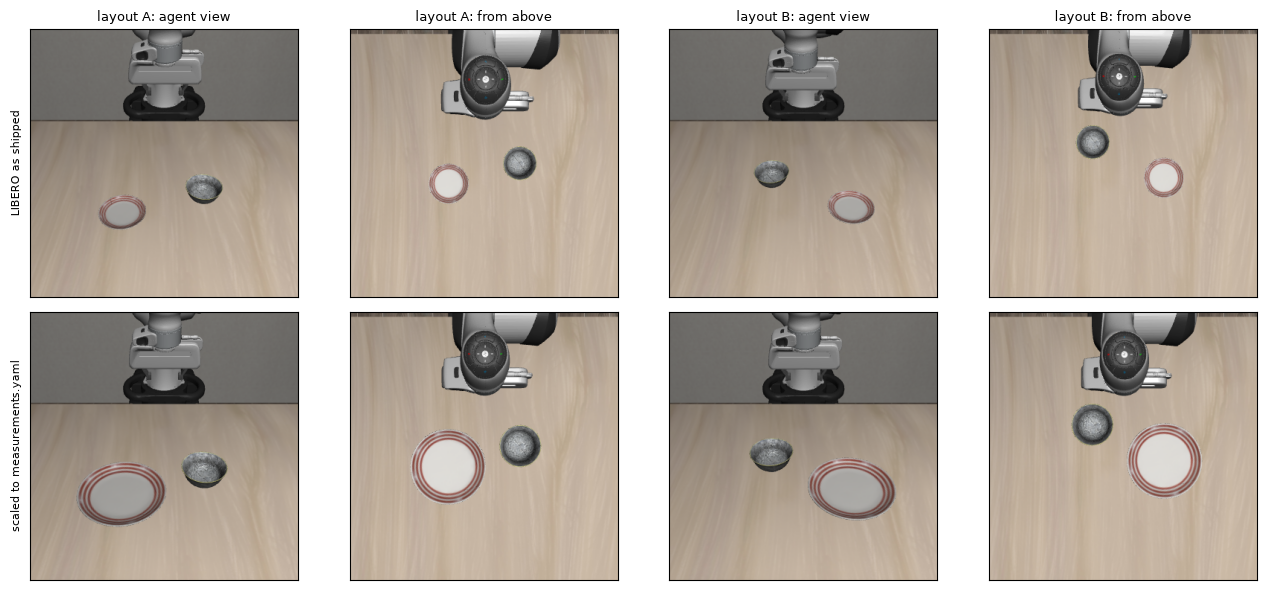

In [5]:
import numpy as np

from hurobo.scaled_native import SimLayout
from hurobo.utils.plotting import plot_image_grid, plot_image_row

layouts = {
    "layout A": SimLayout(bowl_xy=np.array([-0.05, 0.12]), plate_xy=np.array([0.02, -0.12])),
    "layout B": SimLayout(bowl_xy=np.array([-0.12, -0.10]), plate_xy=np.array([0.0, 0.14])),
}
rows = {"LIBERO as shipped": [], "scaled to measurements.yaml": []}
columns = []
for name, layout in layouts.items():
    for label, scaled in (("LIBERO as shipped", False), ("scaled to measurements.yaml", True)):
        scene.reset(layout, scaled=scaled)
        rows[label] += [scene.task.render_camera("agentview", 360, 360), scene.render_top_down(360)]
    columns += [f"{name}: agent view", f"{name}: from above"]
plot_image_grid(rows, columns, cell_in=3.0)

## 2. Why the other five objects are parked

`libero_goal` task 8 also has a cream cheese, a wine bottle, a wooden cabinet, a stove and a wine rack, in fixed places. LIBERO's init ranges (2 cm) were made for its small plate. With the real-size plate (25.5 cm) almost no bowl/plate placement fits between them:

In [6]:
from hurobo.scaled_native import layout_feasible_fraction

footprints = scene.distractor_footprints()
for name, (x0, x1, y0, y1) in footprints.items():
    print(f"{name:26s} x [{x0:+.2f}, {x1:+.2f}]  y [{y0:+.2f}, {y1:+.2f}]")
args = (scene.workspace, setup.bowl.radius_m, setup.plate.radius_m)
print(
    "feasible bowl/plate placements with the other objects in place: "
    f"{layout_feasible_fraction(*args, footprints):.2%}"
)
print(
    "feasible bowl/plate placements with the table cleared:           "
    f"{layout_feasible_fraction(*args, {}):.0%}"
)

cream_cheese_1_main        x [-0.10, -0.02]  y [+0.10, +0.14]
wine_bottle_1_main         x [-0.22, -0.18]  y [-0.08, -0.03]
wooden_cabinet_1_main      x [-0.10, +0.15]  y [-0.35, -0.13]
flat_stove_1_main          x [-0.47, -0.17]  y [+0.12, +0.31]
wine_rack_1_main           x [-0.39, -0.12]  y [-0.39, -0.13]
feasible bowl/plate placements with the other objects in place: 0.00%
feasible bowl/plate placements with the table cleared:           38%


So `ScaledNativeScene` moves them 8 m away and turns their collisions off (`keep_distractors=True` leaves them). This is a deliberate departure from "native"; it is recorded in the design log (D-010).

## 3. Where the real table sits in the sim

The table frame is the one the scans use: origin at the ChArUco board's top-left corner, x along the long side, y toward the far edge, z up with the tabletop at 0. The sim has the robot's base at world x = -0.66 reaching along +x, so "away from the person" is mapped to "away from the robot base". A measured reach map says where the Panda can hold its fingers upright, and so how large the work area may be.

In [7]:
from hurobo.reach import measure_reach_map
from hurobo.utils.viewer import reach_map_figure

xs = np.arange(-0.20, 0.151, 0.05)
ys = np.arange(-0.40, 0.401, 0.10)
reach = {f"fingertips {z:.2f} m up": measure_reach_map(scene, xs, ys, z) for z in (0.94, 1.05)}
reach_map_figure(xs, ys, reach, "Panda position error to each point (home orientation)").show()

In [8]:
from hurobo.capture_plan import workspace_rect_table
from hurobo.scaled_native import table_to_world_map

mapping = table_to_world_map(setup, scene.workspace)
print("work area (world x, y):", scene.workspace.x_range, scene.workspace.y_range)
print(
    "work area (table x_min, x_max, y_min, y_max):", np.round(workspace_rect_table(setup, scene.workspace), 3)
)
print("table centre -> world:", mapping.point_to_world(np.array([*setup.table.centre_xy_m, 0.0])).round(3))
print("rotation table -> world (yaw):", round(float(np.degrees(mapping.yaw_rad))), "deg")

work area (world x, y): (-0.18, 0.08) (-0.25, 0.25)
work area (table x_min, x_max, y_min, y_max): [ 0.442  0.943 -0.41  -0.15 ]
table centre -> world: [-0.05  0.    0.9 ]
rotation table -> world (yaw): -90 deg


## 4. The recording plan

`CapturePlanner` draws layouts from a low-discrepancy sequence inside the work area, so the planned bowl and plate positions cover it evenly and are all valid in the sim. Hand starts and the side of the rim to pinch are balanced across the clips.

In [9]:
from hurobo.camera import CameraIntrinsics
from hurobo.capture_plan import CameraPlacementSearch, CapturePlanner, plan_rows, stand_in_demos
from hurobo.utils.viewer import capture_plan_figure

intrinsics = CameraIntrinsics.load(ROOT / "data/camera_intrinsics_s10e.npz")
placements = CameraPlacementSearch(setup, scene.workspace, intrinsics, min_board_width_px=250).search()
camera = placements[0]
planner = CapturePlanner(setup, scene.workspace, seed=0)
clips = planner.plan(12)
hand_starts = {c.hand_start.name: planner.hand_start_table(c.hand_start)[:2] for c in clips}
capture_plan_figure(setup, workspace_rect_table(setup, scene.workspace), clips, camera, hand_starts).show()

In [10]:
pd.DataFrame(plan_rows(clips, setup)).set_index("clip")

,bowl: cm from left edge,bowl: cm from your edge,plate: cm from left edge,plate: cm from your edge,hand starts,pinch rim on your
clip,,,,,,
clip_001,95,20,59,25,low-near-left,right
clip_002,83,29,52,34,low-near-right,left
clip_003,50,42,60,19,high-over-workspace,right
clip_004,63,24,89,23,low-far-right,left
clip_005,52,19,94,36,mid-left,right
clip_006,93,25,66,31,mid-near,right
clip_007,76,22,51,27,low-near-left,left
clip_008,87,35,57,37,low-near-right,right
clip_009,70,42,93,32,high-over-workspace,left


### The phone

The search keeps poses from which the board (at least 250 px wide), both objects' whole footprint and the hand's reach (up to 30 cm above the table) are in the frame, the line of sight is at least 35 degrees down, and the tripod is not on the table. The best ones are on the **far side**, opposite you, looking back at the table and at the board in the near corner:

In [11]:
print(f"{len(placements)} feasible poses; best five (table frame, metres above the tabletop):")
for p in placements[:5]:
    x, y, z = p.position_table
    print(
        f"  lens x={x:+.2f} y={y:+.2f} z={z:.2f}  board {p.board_width_px:.0f} px  "
        f"hand {p.hand_width_px:.0f} px  looks down {p.elevation_deg:.0f} deg  margin {p.min_margin:.0%}"
    )

168 feasible poses; best five (table frame, metres above the tabletop):
  lens x=+0.47 y=-1.38 z=0.95  board 254 px  hand 91 px  looks down 39 deg  margin 11%
  lens x=+0.47 y=-1.28 z=1.05  board 258 px  hand 91 px  looks down 44 deg  margin 11%
  lens x=+0.37 y=-1.38 z=0.95  board 261 px  hand 90 px  looks down 38 deg  margin 11%
  lens x=+0.37 y=-1.28 z=1.05  board 265 px  hand 90 px  looks down 44 deg  margin 11%
  lens x=+0.57 y=-1.38 z=0.85  board 254 px  hand 96 px  looks down 36 deg  margin 11%


What the scaled sim looks like from that phone pose (the sim's twin camera placed there; the board is not modelled):

.venv/lib/python3.12/site-packages/robosuite/utils/binding_utils.py:1010: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  self.qpos[addr] = value


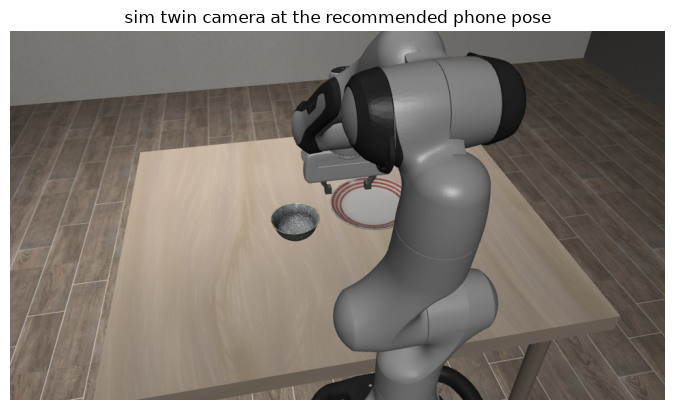

In [12]:
from hurobo.teleop import place_twin_camera

scene.reset(SimLayout(bowl_xy=np.array([-0.05, 0.12]), plate_xy=np.array([0.02, -0.12])))
place_twin_camera(scene.task, mapping, camera.t_table_cam, intrinsics.fovy_degrees)
phone_view = scene.task.render_camera(scene.task.TWIN_CAMERA_NAME, 960, 540)
plot_image_row({"sim twin camera at the recommended phone pose": phone_view}, height_in=4.2)

### What gets printed and stuck on

The table frame is the ChArUco board on the tablet, exactly as in the scans, so nothing is added to the table. The **plate** gets one 6 cm marker (id 22) on its middle. The **bowl** stands on a printed **pad**: a 6 cm marker (id 21) with a circle where the bowl goes, 11.5 cm to its right. The pad's marker lies on the table, so it is never hidden by the bowl or the hand; the bowl's centre is the marker plus that fixed offset.

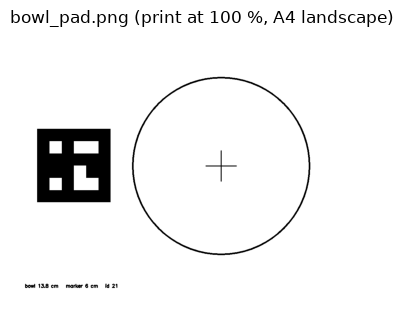

In [13]:
from hurobo.recording import RecordingSpec, render_bowl_pad

spec = RecordingSpec()
pad = render_bowl_pad(spec, setup.bowl.diameter_m, dpi=100)
plot_image_row({"bowl_pad.png (print at 100 %, A4 landscape)": pad}, cmap="gray", height_in=3.2)

### Checking a test clip: where does it go wrong?

`scripts/17_check_capture.py` prints what to fix; this shows *where in the clip* it happens. `diagnose_capture` keeps every frame's detections: ChArUco corners, the bowl-pad and plate markers, the hand, and the pinch aperture. Change `CLIP` to look at another clip.

In [14]:
from hurobo.recording import diagnose_capture
from hurobo.utils.notebook import existing_paths

CLIP = "test"
clip_path = existing_paths(
    {CLIP: ROOT / "data/raw/e1" / f"{CLIP}.mp4"}, "record a test clip into data/raw/e1/"
)[CLIP]
phone_intrinsics = CameraIntrinsics.load(ROOT / "data/camera_intrinsics_s10e.npz")
diagnosis = diagnose_capture(clip_path, phone_intrinsics, setup)
print("\n".join(diagnosis.report.problems) or "PASS")

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792176942.300130  108670 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792176942.305206  108670 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792176942.415524  108672 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


W0000 00:00:1792176971.655487  109235 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792176971.665355  109235 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


hand detected in 75% of frames
hand lost for 1.47s (> 0.4s)
no grasp detected


Top lane group: green square = found, red cross = missing in that frame. The blue band is the first second, where the pad and plate markers must be visible. The red band is the longest hand dropout. Middle: a grasp needs the aperture under the lower dashed line, a release over the upper one. Bottom: how well the hand fit matches (a high value means the depth is unreliable).

In [15]:
from hurobo.utils.viewer import capture_diagnosis_figure

capture_diagnosis_figure(diagnosis).show()

The frames behind it, with the detections drawn (marker outlines with their ids, the hand skeleton) and the caption listing what is missing. Compare the hand dropout frames with the ones just before and after.

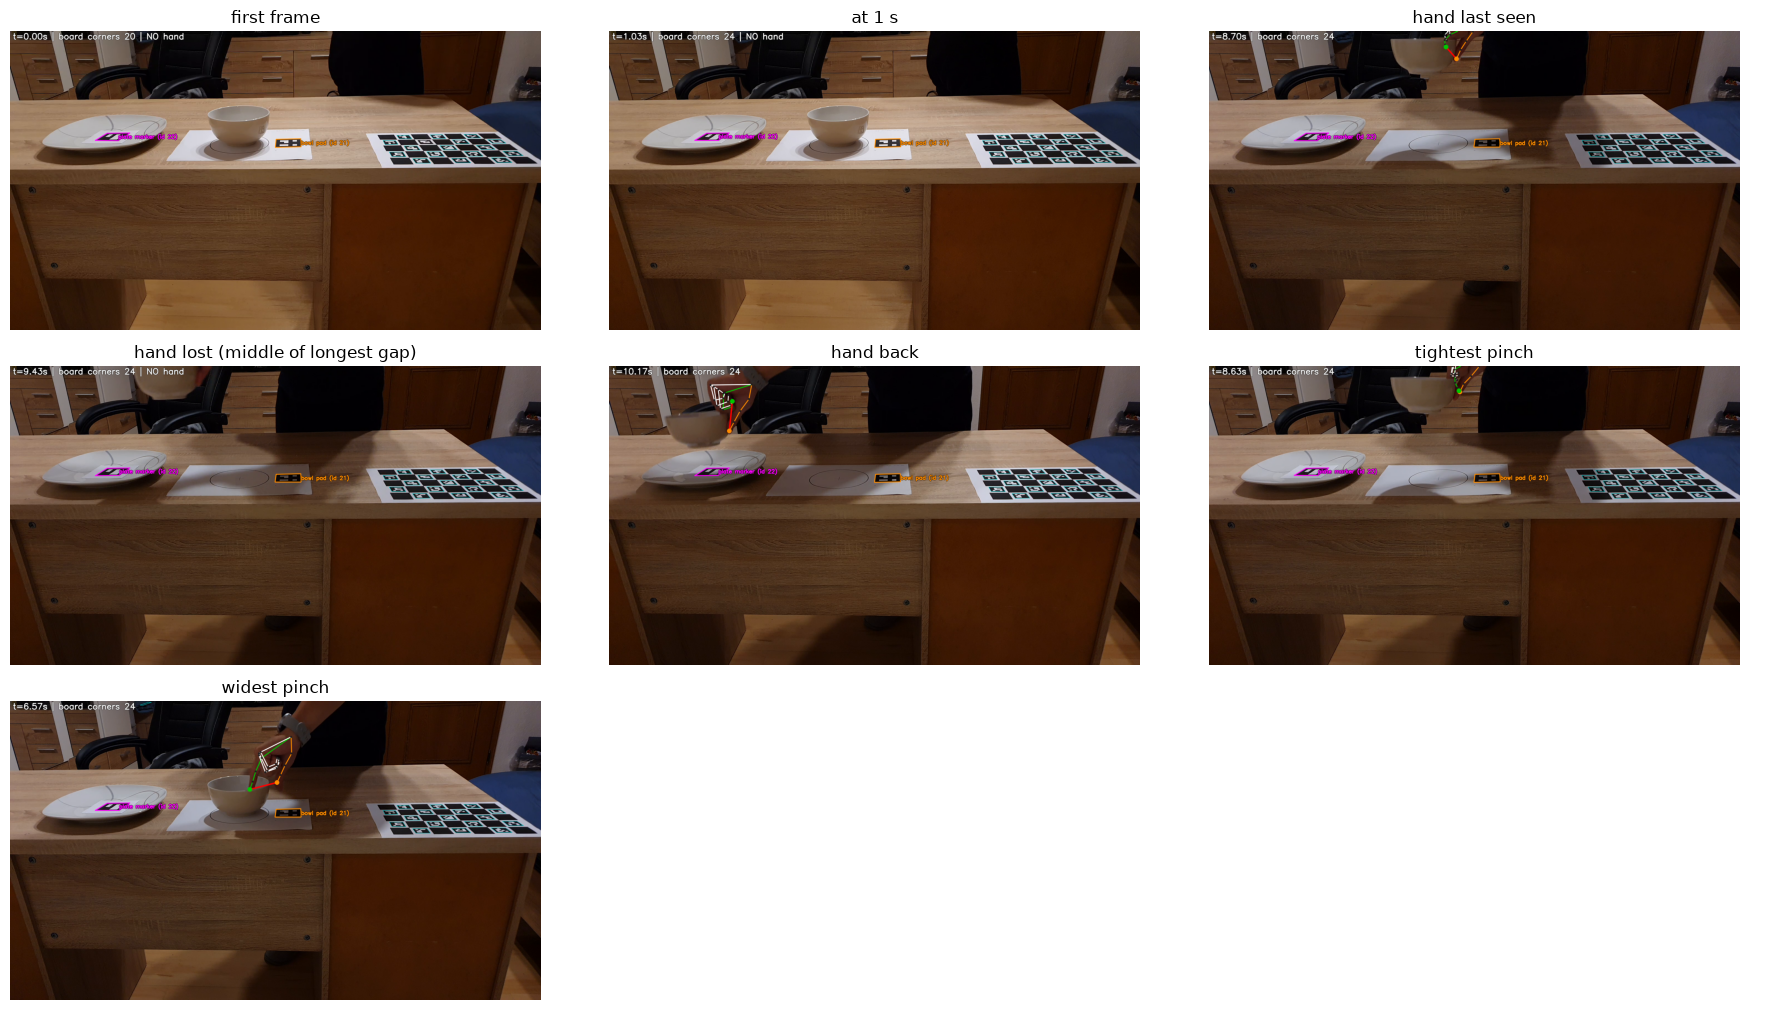

In [16]:
plot_image_row(diagnosis.annotated_frames(diagnosis.key_moments()), height_in=3.4, columns=3)

The same thing as a video: every frame with the detections drawn (bowl pad orange, plate marker magenta, board markers cyan, hand skeleton), a status panel (green = found, red = missing), a red banner when the hand is lost, and a strip along the bottom with the whole clip's detections and a cursor. Lanes in the strip, top to bottom: hand, plate marker, bowl pad, board.\n

In [17]:
from hurobo.utils.notebook import show_video

show_video(diagnosis.write_video(ROOT / "results/capture_check" / f"{CLIP}_diagnosis.mp4"), width=720)

## 5. The commands

One list, used by the guide and the scripts:

In [18]:
from hurobo.recording import session_commands

for what, command in session_commands():
    print(f"# {what}\n{command}\n")

# 1. plan: phone pose, layouts and hand starts, plus the pad and plate marker to print
uv run python scripts/16_plan_recording.py --setup data/raw/setup_01/measurements.yaml --intrinsics data/camera_intrinsics_s10e.npz --clips 20 --out data/raw/e1

# 2. check a 10 s test clip before recording the session
uv run python scripts/17_check_capture.py data/raw/e1/test.mp4 --setup data/raw/setup_01/measurements.yaml --intrinsics data/camera_intrinsics_s10e.npz

# 3. clean the clips: propose a cut per clip (one hand, one close-open cycle), then review them
uv run python scripts/20_clean_clips.py data/raw/e1 --setup data/raw/setup_01/measurements.yaml --intrinsics data/camera_intrinsics_s10e.npz
uv run python scripts/21_clip_cutter.py data/raw/e1 --setup data/raw/setup_01/measurements.yaml --intrinsics data/camera_intrinsics_s10e.npz

# 4. after recording: human clips to table-frame demos + QC report (inside the cuts)
uv run python scripts/02_extract_demos.py data/raw/e1/clip_*.mp4 --setup data

## 6. From a human demo to a robot demo that starts at home

`synthetic_pick_place_demo` stands in for an extracted clip: the hand starts in different places, pinches the rim on the left or right, carries the bowl so that it ends centred on the plate, and lets go. `ObjectCentricRetargeter` then keeps only the part of the approach within 20 cm of the grasp, snaps the grasp onto the rim, bends the carry path so it starts at the bowl and ends centred on the plate, and `PlanExecutor` drives the robot there **from its home pose**.

In [19]:
import tempfile
from pathlib import Path

from hurobo.generate import DemoGenerator

work = Path(tempfile.mkdtemp(prefix="hurobo_e1_"))
demos = stand_in_demos(clips[:4], planner)
generator = DemoGenerator(scene, demos, seed=0)
print("hand starts of the 4 demos:", [c.hand_start.name for c in clips[:4]])

hand starts of the 4 demos: ['low-near-left', 'low-near-right', 'high-over-workspace', 'low-far-right']


In [20]:
from hurobo.utils.viewer import trajectories_figure

paths, results = {}, []
for index, demo in enumerate(demos):
    layout = generator.layout_of_demo(demo)
    result, eef_path = generator.rollout_with_video(demo, work / f"twin_{index}.mp4", layout)
    paths[f"human {index} (world frame)"] = mapping.point_to_world(demo.tcp_pos_table)
    paths[f"robot {index}"] = eef_path
    results.append((index, result.success, result.steps))
print("twin replays (human layout, robot from home):", results)
trajectories_figure(paths, "Human hands start anywhere; the robot always starts at home").show()

.venv/lib/python3.12/site-packages/robosuite/utils/binding_utils.py:1010: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  self.qpos[addr] = value


twin replays (human layout, robot from home): [(0, True, 257), (1, True, 263), (2, True, 228), (3, True, 242)]


Robot's view of the first replay (phases captioned):

In [21]:
from hurobo.utils.notebook import show_video

show_video(work / "twin_0.mp4", width=480)

## 7. How often it works on new layouts

Generation draws a demo and a **new** random layout, retargets, rolls out and keeps the run only if LIBERO's success check fires (bowl within 3 cm of the plate's centre and touching it). This is the success rate of retargeting itself, with a perfect "human" input.

In [22]:
outcomes = []
for _ in range(8):
    demo = demos[int(np.random.default_rng(len(outcomes)).integers(len(demos)))]
    steps, executor = generator.rollout(demo)
    for _step in steps:
        pass
    outcomes.append(executor.result)
wins = sum(r.success for r in outcomes)
print(f"{wins}/{len(outcomes)} succeeded; steps per episode: {[r.steps for r in outcomes]}")
print("failures:", [r.failure for r in outcomes if not r.success])

8/8 succeeded; steps per episode: [290, 282, 290, 302, 281, 239, 285, 277]
failures: []


Larger runs (30 and 40 rollouts, several seeds) are in the design log, D-010. They use the same executor; the notebook keeps eight so it runs in a few minutes.

## 8. Next: generate, train, evaluate

```bash
# robot dataset (needs the real demos from step 3 of the commands above)
MUJOCO_GL=egl uv run python scripts/04_generate_dataset.py data/e1/demos --count 200 --out data/e1/generated
```

Training and evaluation: see the guide. The generated dataset has the feature names of LIBERO's LeRobot datasets, images turned the way `lerobot-eval` turns them, and an 8-d state computed with the same formula. **Evaluation has to run through our own loop**: `lerobot-eval` builds the stock environment on every reset, which would undo the rescaling. That loop is not written yet.